# ПЗ-2. CLIP и SigLIP

## 1. Цель
Сравнить zero-shot классификацию и обучение проекций с двумя контрастными потерями.

## 2. Датасеты и модели
CIFAR-10 test: все 10000 изображений. COCO 2017: 5000 пар train и отдельные 1000 пар val, по одной подписи на уникальное изображение. Дубликаты изображения между выборками исключены. Обучение: 5 эпох для каждого сочетания loss и B.

[CLIP](https://huggingface.co/openai/clip-vit-base-patch32), [SigLIP](https://huggingface.co/google/siglip-base-patch16-224).

Источник задания: `Практика_06_11_2026_1_week.docx`. Приложения А.1–А.7 отсутствуют; ниже приведены стандартные реализации. LoRA-проект не входит в эти шесть работ.

## 3. Подготовка окружения
Откройте этот notebook в Google Colab. Для ПЗ-1 выберите CPU, для ПЗ-3–6 — T4; для ПЗ-2 GPU ускорит получение признаков. Выполните установку, перезапустите сеанс, затем выполните остальные ячейки сверху вниз. Все результаты сохраняются в папке задания; скачайте её вместе с ноутбуком. Данные и веса кэшируются в соседней папке `data`. При переносе в Colab прежние результаты доступны только после загрузки файлов. GPU использует fp16. Числа в сохранённых выводах относятся только к реально выполненным ячейкам. Ячейки без execution_count не запускались.

In [ ]:
%pip install torch==2.9.1 torchvision==0.24.1 transformers==4.57.6 numpy==2.3.5 pandas==2.3.3 matplotlib==3.10.8 pillow==12.0.0 datasets==4.4.1 accelerate==1.12.0 sentencepiece==0.2.1 scikit-learn==1.7.2 pycocoevalcap==1.2 reportlab==4.4.5 huggingface-hub==0.36.2 safetensors==0.8.0 tokenizers==0.22.2 protobuf==6.33.2 ftfy==6.3.1 requests==2.34.2 fsspec==2025.10.0 pyarrow==26.0.1

In [1]:
LAB = 'PZ_2'
REVISIONS = {'facebook/dino-vitb16': 'f205d5d8e640a89a2b8ef0369670dfc37cc07fc2', 'openai/clip-vit-base-patch32': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268', 'google/siglip-base-patch16-224': '7fd15f0689c79d79e38b1c2e2e2370a7bf2761ed', 'Qwen/Qwen2.5-0.5B-Instruct': '7ae557604adf67be50417f59c2c2f167def9a775', 'Qwen/Qwen2.5-VL-3B-Instruct': '66285546d2b821cf421d4f5eb2576359d3770cd3', 'lmms-lab-encoder/DocVQA': '539088ef8a8ada01ac8e2e6d4e372586748a265e', 'lmms-lab-encoder/RefCOCO': 'a5dff0b3194715fda69b2d6a0d2aaafb41eaa407'}

import os
import sys
import json
import random
import time
import math
import gc
import hashlib
import platform
import importlib.metadata
from pathlib import Path
from collections import defaultdict, Counter
from concurrent.futures import ThreadPoolExecutor

ROOT = Path.cwd() if Path.cwd().name == LAB else Path.cwd() / LAB
ROOT.mkdir(exist_ok=True)
OUT = ROOT / "results"
OUT.mkdir(exist_ok=True)
DATA = ROOT.parent / "data"
DATA.mkdir(exist_ok=True)
os.environ["HF_HOME"] = str(DATA / "huggingface")
os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(8, os.cpu_count() or 1))
torch.use_deterministic_algorithms(True, warn_only=True)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.backends.cudnn.benchmark = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32

def save_json(name, value):
    path = OUT / name
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")
    for attempt in range(20):
        try:
            temporary.replace(path)
            return
        except PermissionError:
            if attempt==19:
                raise
            time.sleep(0.1)

def save_figure(name):
    plt.savefig(OUT / name, dpi=130, bbox_inches="tight")
    plt.show()

versions = {p.metadata["Name"]: p.version for p in importlib.metadata.distributions() if p.metadata["Name"]}
environment = {"python": sys.version, "platform": platform.platform(), "seed": SEED,
               "device": str(DEVICE), "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
               "versions": versions, "revisions": REVISIONS}
save_json("environment.json", environment)
print({k: v for k, v in environment.items() if k != "versions"})

{'python': '3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)]', 'platform': 'Windows-11-10.0.26200-SP0', 'seed': 42, 'device': 'cpu', 'gpu': None, 'revisions': {'facebook/dino-vitb16': 'f205d5d8e640a89a2b8ef0369670dfc37cc07fc2', 'openai/clip-vit-base-patch32': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268', 'google/siglip-base-patch16-224': '7fd15f0689c79d79e38b1c2e2e2370a7bf2761ed', 'Qwen/Qwen2.5-0.5B-Instruct': '7ae557604adf67be50417f59c2c2f167def9a775', 'Qwen/Qwen2.5-VL-3B-Instruct': '66285546d2b821cf421d4f5eb2576359d3770cd3', 'lmms-lab-encoder/DocVQA': '539088ef8a8ada01ac8e2e6d4e372586748a265e', 'lmms-lab-encoder/RefCOCO': 'a5dff0b3194715fda69b2d6a0d2aaafb41eaa407'}}


C:\Users\darri\PycharmProjects\cv061126\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from xml.sax.saxutils import escape
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image as PDFImage
from reportlab.lib.styles import ParagraphStyle
from reportlab.lib import colors
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont
from matplotlib import font_manager

def write_report(title, goal, work, findings, table=None, figure=None):
    pdfmetrics.registerFont(TTFont("Student", font_manager.findfont("DejaVu Sans")))
    style = ParagraphStyle("Student", fontName="Student", fontSize=10, leading=14, spaceAfter=8)
    heading = ParagraphStyle("Heading", parent=style, fontSize=14, leading=18, spaceAfter=12)
    story = [Paragraph(escape(title), heading), Paragraph(escape("Цель. " + goal), style),
             Paragraph(escape("Что было сделано. " + work), style)]
    for text in findings:
        story.append(Paragraph(escape(text), style))
    if table is not None and len(table):
        rows = [[Paragraph(escape(str(x)), style) for x in table.columns]]
        rows += [[Paragraph(escape(f"{x:.4f}" if isinstance(x, float) else str(x)), style) for x in row]
                 for row in table.itertuples(index=False, name=None)]
        item = Table(rows, repeatRows=1, colWidths=[495 / len(table.columns)] * len(table.columns))
        item.setStyle(TableStyle([("VALIGN", (0,0), (-1,-1), "TOP"),
                                 ("GRID", (0,0), (-1,-1), 0.3, colors.grey)]))
        story.extend([item, Spacer(1, 10)])
    if figure is not None and Path(figure).exists():
        with Image.open(figure) as im:
            ratio = im.height / im.width
        story.append(PDFImage(str(figure), width=460, height=min(250, 460 * ratio)))
    story.append(Paragraph(escape("Индивидуальный вклад. Подготовлены реализации, протоколы экспериментов, тесты и оформление. Код и текст подготовлены с помощью ИИ-ассистента; фактические запуски и ограничения перечислены выше. Авторство невыполненных опытов не заявляется."), style))
    story.append(Paragraph(escape("Воспроизведение: notebook " + LAB + ".ipynb; seed=42. Версии среды и точные ревизии весов сохранены в results/environment.json. Контрольные вопросы разобраны в ноутбуке."), style))
    SimpleDocTemplate(str(ROOT / "report.pdf"), pagesize=(595,842), rightMargin=50, leftMargin=50,
                      topMargin=45, bottomMargin=45).build(story)
    print("PDF:", ROOT / "report.pdf")

In [3]:
import requests
from zipfile import ZipFile

def download(url, destination):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists():
        return destination
    temporary = destination.with_suffix(destination.suffix + ".part")
    for attempt in range(4):
        try:
            with requests.get(url, stream=True, timeout=(20, 120)) as response:
                response.raise_for_status()
                with temporary.open("wb") as stream:
                    for block in response.iter_content(1024 * 1024):
                        stream.write(block)
            temporary.replace(destination)
            return destination
        except requests.RequestException:
            if attempt == 3:
                raise
            time.sleep(attempt + 1)

def coco_annotations(year=2017):
    archive = download(f"https://s3.amazonaws.com/images.cocodataset.org/annotations/annotations_trainval{year}.zip",
                       DATA / f"annotations_trainval{year}.zip")
    with ZipFile(archive) as z:
        for name in z.namelist():
            if name.startswith("annotations/") and name.endswith(".json"):
                target = DATA / name
                if not target.exists():
                    target.parent.mkdir(exist_ok=True)
                    target.write_bytes(z.read(name))
    manifest = {"url": f"https://s3.amazonaws.com/images.cocodataset.org/annotations/annotations_trainval{year}.zip",
                "sha256": hashlib.file_digest(archive.open("rb"), "sha256").hexdigest()}
    save_json(f"coco{year}_source.json", manifest)

def caption_pairs(split, count, seed=SEED):
    data = json.loads((DATA / "annotations" / f"captions_{split}2017.json").read_text())
    captions = defaultdict(list)
    for ann in data["annotations"]:
        captions[ann["image_id"]].append(ann)
    ids = sorted(captions)
    rng = random.Random(seed)
    rng.shuffle(ids)
    selected = ids[:count]
    assert len(selected) == count
    records = []
    for image_id in selected:
        refs = sorted(captions[image_id], key=lambda a: a["id"])
        target = rng.choice(refs)
        records.append({"image_id": image_id, "caption_id": target["id"], "caption": target["caption"],
                        "references": [r["caption"] for r in refs], "split": split})
    return records

def coco_image(record, year=2017):
    split = record["split"]
    image_id = record["image_id"]
    name = f"{image_id:012d}.jpg" if year == 2017 else f"COCO_{split}{year}_{image_id:012d}.jpg"
    path = download(f"https://s3.amazonaws.com/images.cocodataset.org/{split}{year}/{name}", DATA / f"{split}{year}" / name)
    with Image.open(path) as image:
        return image.convert("RGB")

def load_images(records):
    with ThreadPoolExecutor(max_workers=8) as pool:
        return list(pool.map(coco_image, records))

## 4. Реализация
Используется scale = exp(log_scale) = 1/τ. При увеличении τ softmax становится равномернее, поэтому фраза о большой температуре в исходном DOCX математически неточна. Тест увеличивает обратную температуру. SigLIP суммирует бинарные потери по всем B² парам и делит на B, как в статье; деление на B² меняло бы масштаб градиентов при смене батча.

In [4]:
def clip_loss(image, text, scale):
    logits = scale * F.normalize(image, dim=-1) @ F.normalize(text, dim=-1).T
    target = torch.arange(len(image), device=image.device)
    return (F.cross_entropy(logits, target) + F.cross_entropy(logits.T, target)) / 2

def siglip_loss(image, text, scale, bias):
    logits = scale * F.normalize(image, dim=-1) @ F.normalize(text, dim=-1).T + bias
    signs = 2*torch.eye(len(image), device=image.device)-1
    return -F.logsigmoid(signs*logits).sum()/len(image)

def retrieval(image, text):
    scores = F.normalize(image.float(), dim=-1) @ F.normalize(text.float(), dim=-1).T
    correct = torch.arange(len(image), device=scores.device)[:,None]
    result = {}
    for direction, matrix in [("i2t",scores),("t2i",scores.T)]:
        for k in [1,5]:
            result[f"{direction}_R{k}"] = (matrix.topk(k, dim=1).indices == correct).any(1).float().mean().item()
    return result

In [5]:
torch.manual_seed(SEED)
single = clip_loss(torch.randn(1,64), torch.randn(1,64), 10.)
assert single.item() == 0
separated = torch.linalg.qr(torch.randn(64,16)).Q.T
loss_values = [clip_loss(separated, separated, scale).item() for scale in [1.,10.,100.]]
assert loss_values[0] > loss_values[1] > loss_values[2]
assert loss_values[-1] < 1e-6
x = torch.randn(8,64,requires_grad=True)
y = torch.randn(8,64,requires_grad=True)
sigmoid_value = siglip_loss(x,y,10.,-10.)
sigmoid_value.backward()
assert torch.isfinite(x.grad).all() and x.grad.abs().sum() > 0
target = torch.eye(8)
logits = 10*F.normalize(x.detach(),dim=1) @ F.normalize(y.detach(),dim=1).T-10
assert torch.allclose(sigmoid_value.detach(), F.binary_cross_entropy_with_logits(logits,target,reduction="sum")/8)
unit_results = {"B1_InfoNCE":single.item(),"InfoNCE_scales_1_10_100":loss_values,
                "SigLIP_random_loss":sigmoid_value.item(),"gradient_finite":True,"passed":True}
save_json("unit_tests.json",unit_results)
display(unit_results)

{'B1_InfoNCE': 0.0,
 'InfoNCE_scales_1_10_100': [1.874597191810608, 0.000680915080010891, 0.0],
 'SigLIP_random_loss': 10.25728702545166,
 'gradient_finite': True,
 'passed': True}

## 5. Эксперименты
В ансамбле сначала нормируются эмбеддинги пяти фраз, затем усредняются и вновь нормируются. Максимальная точность на test используется только для выбора показываемой confusion matrix; это не независимая оценка выбранного по test шаблона.

`torch_dtype` is deprecated! Use `dtype` instead!


openai/clip-vit-base-patch32: 0it [00:00, ?it/s]

openai/clip-vit-base-patch32: 0it [00:00, ?it/s]

C:\Users\darri\PycharmProjects\cv061126\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\darri\PycharmProjects\cv061126\data\huggingface\hub\models--google--siglip-base-patch16-224. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


google/siglip-base-patch16-224:   0%|          | 0/625 [00:00<?, ?it/s]

google/siglip-base-patch16-224:   0%|          | 1/625 [00:02<25:04,  2.41s/it]

... (622 outputs left out)

google/siglip-base-patch16-224: 100%|█████████▉| 624/625 [31:25<00:02,  2.52s/it]

google/siglip-base-patch16-224: 100%|██████████| 625/625 [31:27<00:00,  2.54s/it]

google/siglip-base-patch16-224: 100%|██████████| 625/625 [31:27<00:00,  3.02s/it]

,model,prompt,accuracy,n
0,openai/clip-vit-base-patch32,class,0.8735,10000
1,openai/clip-vit-base-patch32,photo,0.8880,10000
2,openai/clip-vit-base-patch32,ensemble,0.8913,10000
3,google/siglip-base-patch16-224,class,0.9100,10000
4,google/siglip-base-patch16-224,photo,0.9254,10000
5,google/siglip-base-patch16-224,ensemble,0.9256,10000


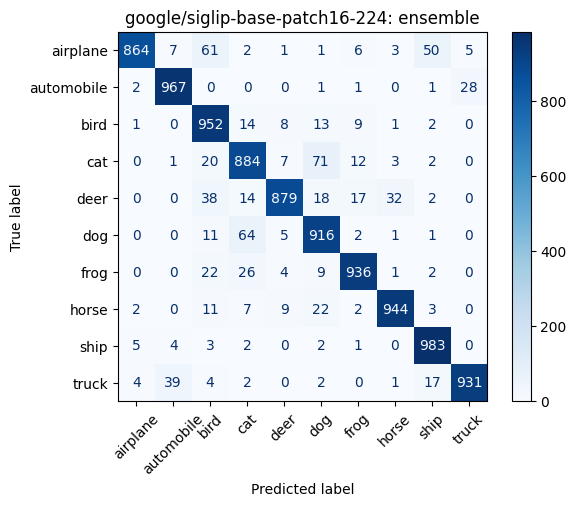

In [6]:
from torchvision.datasets import CIFAR10
from transformers import AutoProcessor, CLIPModel, SiglipModel

templates = ["a photo of a {}", "a blurry photo of a {}", "a close-up photo of a {}",
             "a photo of the {}", "a bright photo of a {}"]
cifar = CIFAR10(str(DATA),train=False,download=True)
truth = np.array(cifar.targets)
zero_rows = []
best_accuracy = -1
for model_id, model_class in [("openai/clip-vit-base-patch32",CLIPModel),
                              ("google/siglip-base-patch16-224",SiglipModel)]:
    processor = AutoProcessor.from_pretrained(model_id,revision=REVISIONS[model_id],use_fast=False)
    model = model_class.from_pretrained(model_id,revision=REVISIONS[model_id],torch_dtype=DTYPE, use_safetensors=(model_class is SiglipModel)).to(DEVICE).eval()
    model.requires_grad_(False)
    text_features = {}
    for variant, patterns in [("class",["{}"]),("photo",templates[:1]),("ensemble",templates)]:
        vectors = []
        for pattern in patterns:
            kwargs = {"padding":"max_length", "max_length":64} if model_class is SiglipModel else {"padding":True}
            batch = processor(text=[pattern.format(c) for c in cifar.classes], return_tensors="pt",truncation=True,**kwargs).to(DEVICE)
            with torch.inference_mode():
                vectors.append(F.normalize(model.get_text_features(**batch).float(),dim=-1))
        text_features[variant] = F.normalize(torch.stack(vectors).mean(0),dim=-1)
    protocol = {"device":str(DEVICE),"dtype":str(DTYPE),"templates":templates,"classes":cifar.classes}
    cache_name = f"cifar_{model_class.__name__}.json"
    cache_path = OUT/cache_name
    cached = json.loads(cache_path.read_text(encoding="utf-8")) if cache_path.exists() else None
    if cached is not None:
        assert cached["revision"]==REVISIONS[model_id] and cached["model"]==model_id
    if cached is not None and cached.get("protocol") != protocol:
        cached = None
    predictions = cached["predictions"] if cached is not None else {name:[] for name in text_features}
    completed = len(predictions["class"])
    assert all(len(v)==completed for v in predictions.values())
    batch_size = 64 if DEVICE.type == "cuda" else 16
    for begin in tqdm(range(completed,len(cifar),batch_size),desc=model_id):
        batch_images = [cifar[i][0] for i in range(begin,min(begin+batch_size,len(cifar)))]
        batch = processor(images=batch_images,return_tensors="pt").to(DEVICE)
        with torch.inference_mode():
            feature = F.normalize(model.get_image_features(pixel_values=batch.pixel_values.to(DTYPE)).float(),dim=-1)
        for variant, vectors in text_features.items():
            predictions[variant].extend((feature @ vectors.T).argmax(1).cpu().tolist())
        save_json(cache_name,{"model":model_id,"revision":REVISIONS[model_id],"protocol":protocol,"predictions":predictions})
    for variant, predicted in predictions.items():
        accuracy = float(np.mean(np.array(predicted)==truth))
        zero_rows.append({"model":model_id,"prompt":variant,"accuracy":accuracy,"n":len(truth)})
        pd.DataFrame({"target":truth,"prediction":predicted}).to_csv(OUT/f"predictions_{model_class.__name__}_{variant}.csv",index=False)
        if accuracy > best_accuracy:
            best_accuracy, best_predictions, best_name = accuracy, predicted, f"{model_id}: {variant}"
    del model
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
zero = pd.DataFrame(zero_rows)
zero.to_csv(OUT/"zero_shot.csv",index=False)
display(zero)
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(truth,best_predictions,display_labels=cifar.classes,xticks_rotation=45,cmap="Blues")
plt.title(best_name)
save_figure("confusion_matrix.png")

In [7]:
coco_annotations()
train_pairs = caption_pairs("train",5000)
test_pairs = caption_pairs("val",1000)
assert not ({r["image_id"] for r in train_pairs} & {r["image_id"] for r in test_pairs})
save_json("pairs_train.json",train_pairs)
save_json("pairs_test.json",test_pairs)
model_id = "openai/clip-vit-base-patch32"
processor = AutoProcessor.from_pretrained(model_id,revision=REVISIONS[model_id],use_fast=False)
encoder = CLIPModel.from_pretrained(model_id,revision=REVISIONS[model_id],torch_dtype=DTYPE,use_safetensors=False).to(DEVICE).eval()
encoder.requires_grad_(False)
for split, records in [("train",train_pairs),("test",test_pairs)]:
    features_image, features_text = [], []
    for begin in tqdm(range(0,len(records),32),desc=f"CLIP {split}"):
        chunk = records[begin:begin+32]
        images = load_images(chunk)
        batch = processor(images=images,text=[r["caption"] for r in chunk],padding=True,truncation=True,
                          max_length=77,return_tensors="pt").to(DEVICE)
        with torch.inference_mode():
            features_image.append(encoder.get_image_features(pixel_values=batch.pixel_values.to(DTYPE)).float().cpu())
            features_text.append(encoder.get_text_features(input_ids=batch.input_ids,attention_mask=batch.attention_mask).float().cpu())
    torch.save({"image":torch.cat(features_image),"text":torch.cat(features_text),
                "image_ids":[r["image_id"] for r in records],"revision":REVISIONS[model_id]},OUT/f"features_{split}.pt")
del encoder
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

CLIP train:   0%|          | 0/157 [00:00<?, ?it/s]

CLIP train:   1%|          | 1/157 [00:01<04:58,  1.91s/it]

CLIP train:   1%|▏         | 2/157 [00:03<04:27,  1.73s/it]

CLIP train:   2%|▏         | 3/157 [00:05<04:14,  1.65s/it]

CLIP train:   3%|▎         | 4/157 [00:06<04:11,  1.65s/it]

CLIP train:   3%|▎         | 5/157 [00:08<04:21,  1.72s/it]

... (183 outputs left out)

CLIP test:  94%|█████████▍| 30/32 [00:52<00:03,  1.74s/it]

CLIP test:  97%|█████████▋| 31/32 [00:53<00:01,  1.72s/it]

CLIP test: 100%|██████████| 32/32 [00:54<00:00,  1.34s/it]

CLIP test: 100%|██████████| 32/32 [00:54<00:00,  1.70s/it]

In [8]:
train = torch.load(OUT/"features_train.pt",weights_only=True)
test = torch.load(OUT/"features_test.pt",weights_only=True)
assert len(train["image"]) == 5000 and len(test["image"]) == 1000
x_train, y_train = train["image"].to(DEVICE), train["text"].to(DEVICE)
x_test, y_test = test["image"].to(DEVICE), test["text"].to(DEVICE)
epochs = 5
recall_rows, history = [], []
for loss_name in ["InfoNCE","SigLIP"]:
    for batch_size in [8,32,128,512]:
        torch.manual_seed(SEED)
        image_head = nn.Linear(x_train.shape[1],256).to(DEVICE)
        text_head = nn.Linear(y_train.shape[1],256).to(DEVICE)
        log_scale = nn.Parameter(torch.tensor(math.log(10.),device=DEVICE))
        bias = nn.Parameter(torch.tensor(-10.,device=DEVICE))
        parameters = list(image_head.parameters())+list(text_head.parameters())+[log_scale]
        if loss_name == "SigLIP":
            parameters.append(bias)
        optimizer = torch.optim.AdamW(parameters,lr=1e-3,weight_decay=1e-4)
        scaler = torch.amp.GradScaler("cuda",enabled=DEVICE.type=="cuda")
        generator = torch.Generator().manual_seed(SEED)
        step = 0
        start = time.perf_counter()
        for epoch in range(epochs):
            order = torch.randperm(len(x_train),generator=generator)
            for idx in order.split(batch_size):
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=DEVICE.type=="cuda"):
                    vi, vt = image_head(x_train[idx]), text_head(y_train[idx])
                loss = clip_loss(vi.float(),vt.float(),log_scale.exp()) if loss_name == "InfoNCE" else siglip_loss(vi.float(),vt.float(),log_scale.exp(),bias)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(parameters,1.)
                scaler.step(optimizer)
                scaler.update()
                with torch.no_grad():
                    log_scale.clamp_(math.log(0.01),math.log(100.))
                step += 1
                history.append({"loss":loss_name,"batch":batch_size,"epoch":epoch+1,"step":step,
                                "value":loss.item(),"scale":log_scale.exp().item(),"temperature":(-log_scale).exp().item(),"bias":bias.item()})
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        elapsed = time.perf_counter()-start
        with torch.inference_mode():
            metrics = retrieval(image_head(x_test),text_head(y_test))
        recall_rows.append({"loss":loss_name,"batch":batch_size,"epochs":epochs,"steps":step,"seconds":elapsed,**metrics,
                            "scale":log_scale.exp().item(),"temperature":(-log_scale).exp().item()})
        torch.save({"image_head":image_head.state_dict(),"text_head":text_head.state_dict(),
                    "log_scale":log_scale.detach().cpu(),"bias":bias.detach().cpu()},OUT/f"heads_{loss_name}_{batch_size}.pt")
        pd.DataFrame(recall_rows).to_csv(OUT/"recall.csv",index=False)
        pd.DataFrame(history).to_csv(OUT/"training.csv",index=False)
recall = pd.DataFrame(recall_rows)
display(recall)

,loss,batch,epochs,steps,seconds,i2t_R1,i2t_R5,t2i_R1,t2i_R5,scale,temperature
0,InfoNCE,8,5,3125,6.414658,0.299,0.623,0.281,0.616,27.222706,0.036734
1,InfoNCE,32,5,785,1.768227,0.409,0.742,0.393,0.731,18.137194,0.055135
2,InfoNCE,128,5,200,0.676362,0.457,0.772,0.447,0.776,12.332958,0.081084
3,InfoNCE,512,5,50,0.423452,0.429,0.757,0.427,0.754,10.521695,0.095042
4,SigLIP,8,5,3125,6.502657,0.347,0.685,0.341,0.685,19.448128,0.051419
5,SigLIP,32,5,785,1.807006,0.386,0.735,0.399,0.739,15.988922,0.062543
6,SigLIP,128,5,200,0.669053,0.427,0.758,0.425,0.755,12.173476,0.082146
7,SigLIP,512,5,50,0.412696,0.400,0.722,0.398,0.714,10.374503,0.096390


## 6. Полученные результаты

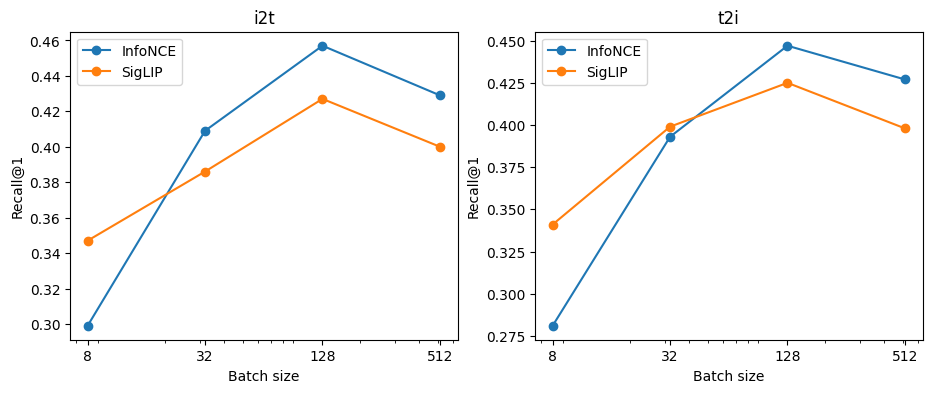

,loss,batch,steps,scale,temperature
0,InfoNCE,8,3125,27.222706,0.036734
1,InfoNCE,32,785,18.137194,0.055135
2,InfoNCE,128,200,12.332958,0.081084
3,InfoNCE,512,50,10.521695,0.095042
4,SigLIP,8,3125,19.448128,0.051419
5,SigLIP,32,785,15.988922,0.062543
6,SigLIP,128,200,12.173476,0.082146
7,SigLIP,512,50,10.374503,0.096390


In [9]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
for direction, ax in zip(["i2t","t2i"],axes):
    for loss_name, group in recall.groupby("loss"):
        ax.plot(group.batch,group[f"{direction}_R1"],"o-",label=loss_name)
    ax.set(xscale="log",xlabel="Batch size",ylabel="Recall@1",title=direction)
    ax.set_xticks([8,32,128,512],[8,32,128,512])
    ax.legend()
save_figure("recall_batch.png")
display(recall[["loss","batch","steps","scale","temperature"]])

## 7. Анализ и выводы
[Статья SigLIP](https://arxiv.org/abs/2303.15343) сообщает об эффективности сигмоидной потери и при меньших батчах. Здесь исследуются только линейные головы поверх уже обученного CLIP, поэтому результат не является повторением предобучения SigLIP. При фиксированных эпохах большие B дают меньше шагов: это смешивающий фактор, явно сохранённый в таблице. Общие параметры оптимизатора не гарантируют оптимальную настройку каждой потери.

In [10]:
comparison = recall.pivot(index="batch",columns="loss",values="i2t_R1")
delta = comparison["SigLIP"]-comparison["InfoNCE"]
analysis_text = (f"В этом запуске преимущество SigLIP по i2t Recall@1 наблюдалось при {int((delta>0).sum())} из {len(delta)} размеров батча. "
                 f"Разности SigLIP−InfoNCE: {delta.round(4).to_dict()}. Это локальный результат для замороженных CLIP-признаков.")
save_json("analysis.json",{"comparison":analysis_text})
display(Markdown(analysis_text))

В этом запуске преимущество SigLIP по i2t Recall@1 наблюдалось при 1 из 4 размеров батча. Разности SigLIP−InfoNCE: {8: 0.048, 32: -0.023, 128: -0.03, 512: -0.029}. Это локальный результат для замороженных CLIP-признаков.

## 8. Контрольные вопросы
**Почему ансамбль помогает?** Усреднение текстовых эмбеддингов уменьшает зависимость от одной формулировки. В сохранённом CPU-запуске CLIP улучшился с 88.80% для photo до 89.13%, а SigLIP — с 92.54% до 92.56%. Улучшение не гарантировано и для SigLIP здесь составляет всего два правильно классифицированных изображения из 10000.

**Как ведёт себя обучаемая температура?** Начальная τ=0.1, обратная температура 1/τ=10. В сохранённом запуске во всех восьми опытах τ уменьшилась: конечный диапазон 0.0367–0.0964. Значит, масштаб логитов вырос, а распределение совпадений стало более резким. Значения на каждом шаге записаны в training.csv; окончательные значения показаны в таблице. Увеличение τ, наоборот, сглаживало бы распределение. Это наблюдение данного запуска, а не общее доказательство монотонного поведения температуры.

In [6]:
unit = json.loads((OUT/"unit_tests.json").read_text(encoding="utf-8"))
findings = [f"Проверки: InfoNCE(B=1)={unit['B1_InfoNCE']}; при масштабах 1, 10, 100: {unit['InfoNCE_scales_1_10_100']}. Градиенты SigLIP конечны."]
complete = (OUT/"recall.csv").exists() and len(pd.read_csv(OUT/"recall.csv")) == 8 and (OUT/"zero_shot.csv").exists()
if complete:
    zero_saved = pd.read_csv(OUT/"zero_shot.csv")
    recall_saved = pd.read_csv(OUT/"recall.csv")
    findings.append("Zero-shot accuracy на 10000 CIFAR-10: "+"; ".join(f"{r.model.split('/')[-1]}, {r.prompt}: {r.accuracy:.4f}" for r in zero_saved.itertuples()))
    findings.append(json.loads((OUT/"analysis.json").read_text(encoding="utf-8"))["comparison"])
    best = recall_saved.loc[recall_saved.i2t_R1.idxmax()]
    findings.append(f"Лучший i2t Recall@1: {best.i2t_R1:.3f}, loss={best.loss}, B={best.batch}. В этом опыте t2i Recall@1={best.t2i_R1:.3f}. Оценка проведена на 1000 отдельных парах COCO.")
    findings.append("Обучались только две линейные головы над замороженными признаками CLIP: 5000 train-пар, 5 эпох. Для B=8/32/128/512 выполнено 3125/785/200/50 шагов. Разный бюджет шагов ограничивает сравнение только по размеру батча.")
    findings.append(f"Температура начиналась с 0.1; конечный диапазон {recall_saved.temperature.min():.4f}–{recall_saved.temperature.max():.4f}. Во всех восьми опытах обратная температура выросла.")
    comparison = recall_saved.pivot(index="batch",columns="loss",values="i2t_R1")
    small_delta = float(comparison.loc[8,"SigLIP"]-comparison.loc[8,"InfoNCE"])
    findings.append(f"При B=8 разность SigLIP−InfoNCE равна {small_delta:+.3f}. Локальное преимущество при малом батче согласуется с направлением выводов статьи SigLIP (arxiv.org/abs/2303.15343). Это не воспроизведение предобучения из статьи: энкодеры заморожены, объём данных меньше, выполнен один seed. Статистическая значимость различий не установлена.")
    table = recall_saved[["loss","batch","steps","i2t_R1","i2t_R5","t2i_R1","t2i_R5"]]
    display(Markdown("\n\n".join(findings[1:])))
else:
    findings += ["Полные эксперименты не выполнены в этой среде. Нет полной таблицы zero-shot accuracy и Recall на 1000 парах; итоговое сравнение моделей пока невозможно.",
                 "Реализован полный протокол: CIFAR-10 test, 5000 обучающих и 1000 проверочных пар COCO, восемь опытов по 5 эпох. Объёмы не сокращены."]
    table = None
write_report("ПЗ-2. CLIP и SigLIP", "Изучить контрастные потери и влияние батча.",
             "Выполнены проверки потерь и доступные этапы полного протокола. Фактические результаты перечислены ниже.",findings,table,OUT/"recall_batch.png")

Zero-shot accuracy на 10000 CIFAR-10: clip-vit-base-patch32, class: 0.8735; clip-vit-base-patch32, photo: 0.8880; clip-vit-base-patch32, ensemble: 0.8913; siglip-base-patch16-224, class: 0.9100; siglip-base-patch16-224, photo: 0.9254; siglip-base-patch16-224, ensemble: 0.9256

В этом запуске преимущество SigLIP по i2t Recall@1 наблюдалось при 1 из 4 размеров батча. Разности SigLIP−InfoNCE: {8: 0.048, 32: -0.023, 128: -0.03, 512: -0.029}. Это локальный результат для замороженных CLIP-признаков.

Лучший i2t Recall@1: 0.457, loss=InfoNCE, B=128. В этом опыте t2i Recall@1=0.447. Оценка проведена на 1000 отдельных парах COCO.

Обучались только две линейные головы над замороженными признаками CLIP: 5000 train-пар, 5 эпох. Для B=8/32/128/512 выполнено 3125/785/200/50 шагов. Разный бюджет шагов ограничивает сравнение только по размеру батча.

Температура начиналась с 0.1; конечный диапазон 0.0367–0.0964. Во всех восьми опытах обратная температура выросла.

При B=8 разность SigLIP−InfoNCE равна +0.048. Локальное преимущество при малом батче согласуется с направлением выводов статьи SigLIP (arxiv.org/abs/2303.15343). Это не воспроизведение предобучения из статьи: энкодеры заморожены, объём данных меньше, выполнен один seed. Статистическая значимость различий не установлена.

PDF: C:\Users\darri\PycharmProjects\cv061126\PZ_2\report.pdf
